# Ettin transformer exits: longer training with a broader data mix

Self-contained Colab A100 notebook. Continue the **trained, independent transformer exit heads** from notebook 04;
keep the original Ettin backbone frozen. No other notebook needs to execute in this kernel.

**Default run:** 3,000 additional updates, batch 32, all existing exits, 128/256/384D, peak LR 3e-5.
Batches follow a 50/25/25 mixture of the existing MS MARCO triplets, SQuAD question–passage pairs,
and AllNLI entailment/contradiction triplets. Fresh optimizer/schedule; preserve the selected source checkpoint's
MS MARCO sample order and cursor. Drive saves restartable checkpoints every 100 updates.

Run all cells in order. Defaults read `ettin-exit-ablation-01` and write a **new** `ettin-transformer-long-01` folder.
Need the ablation's backbone export and transformer checkpoints, plus the original pilot's `pairs.json`.
The final cell performs independent sanity checks. ONNX and shared-head architecture changes are deferred.

In [4]:
# Install into this notebook's kernel. Keep Colab's CUDA-enabled PyTorch.
# Restart the kernel after this cell if it already imported different versions.
%pip install -q transformers==5.1.0 datasets==4.5.0 accelerate==1.12.0 sentence-transformers==5.2.2 safetensors
%pip -q install matplotlib

In [5]:
import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HOME'] = '/content/hf-cache' if os.path.isdir('/content') else '/tmp/encoder-hf-cache'
import copy, gc, hashlib, json, math, random, shutil, time, uuid
from pathlib import Path
from collections import defaultdict
from contextlib import nullcontext
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
from transformers import AutoConfig, AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file, save_file
from tqdm.auto import tqdm
from google.colab import drive

drive.mount('/content/drive')
DEVICE = 'cuda'
assert torch.cuda.is_available(), 'Select an A100 GPU runtime in Colab.'
assert torch.cuda.is_bf16_supported(), 'This notebook uses BF16 on a supported GPU.'
print(torch.cuda.get_device_name(), 'PyTorch:', torch.__version__)
torch.set_float32_matmul_precision('high')
import csv
import matplotlib.pyplot as plt
from transformers.models.modernbert.modeling_modernbert import create_bidirectional_mask, create_bidirectional_sliding_window_mask

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NVIDIA A100-SXM4-40GB PyTorch: 2.11.0+cu128


## Settings
Change settings only with a new `RUN_NAME`. For a smoke run: `ADDITIONAL_STEPS=20`, `BATCH_SIZE=8`,
`NEW_TRAIN_ROWS=256`, `NEW_HOLDOUT_ROWS=32`, `EVAL_EVERY=10`, `CHECKPOINT_EVERY=10`.
Depths, dimensions, tokenizer and input-length cap are inherited from the trained source run.

In [6]:
SOURCE_RUN = Path('/content/drive/MyDrive/encoder_experiments/ettin-exit-ablation-01')
SOURCE_EXPORT = SOURCE_RUN / 'exports' / 'exit-ablation'
SOURCE_SEED = 42
SOURCE_STAGE = f'transformer-seed-{SOURCE_SEED}'
SOURCE_CHOICE = 'best'  # 'best' or 'latest'; selected source identity is locked on first run
PILOT_RUN_OVERRIDE = None  # Normally inferred from the source metadata; set Path(...) if moved.
RUN_NAME = 'ettin-transformer-long-01'
ROOT = Path('/content/drive/MyDrive/encoder_experiments') / RUN_NAME
LOCAL = Path('/content/encoder-work') / RUN_NAME
assert ROOT.resolve()!=SOURCE_RUN.resolve()
ROOT.mkdir(parents=True,exist_ok=True);LOCAL.mkdir(parents=True,exist_ok=True)
ADDITIONAL_STEPS = 3000
BATCH_SIZE = 32
PEAK_LR = 3e-5
MIN_LR_RATIO = .1
WARMUP_STEPS = 100
EVAL_EVERY = 200
CHECKPOINT_EVERY = 100
LOG_EVERY = 25
NEW_TRAIN_ROWS = 30000  # maximum per added dataset, after filtering
NEW_HOLDOUT_ROWS = 128  # per added dataset and split
SEED = 43
MIX_CYCLE = ['msmarco','msmarco','squad','all_nli']
SELECTION_WEIGHTS = dict(msmarco=.5,squad=.25,all_nli=.25)
MAX_MSMARCO_MRR_DROP = .02  # absolute validation-MRR margin relative to source heads
MAX_TEXT_CHARS = 12000
SHUFFLE_BUFFER = 10000
EXTRA_DATA = {
 'squad':dict(id='sentence-transformers/squad',revision='d84c8c2ef64693264c890bb242d2e73fc0a46c40',subset='pair',split='train'),
 'all_nli':dict(id='sentence-transformers/all-nli',revision='d482672c8e74ce18da116f430137434ba2e52fab',subset='triplet',split='train'),
}
NANO = dict(id='sentence-transformers/NanoBEIR-en',revision='beb106fbcfaa599c508c667041bf8c85fd78736b')
def digest(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def text_id(s):
    return hashlib.sha256(' '.join(s.split()).casefold().encode()).hexdigest()
def write_json(path,obj):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(path.name+'.tmp-'+uuid.uuid4().hex)
    temp.write_text(json.dumps(obj,indent=2,ensure_ascii=False));os.replace(temp,path)
def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(8*1024*1024),b''):h.update(part)
    return h.hexdigest()



assert ADDITIONAL_STEPS>0 and BATCH_SIZE>1 and NEW_TRAIN_ROWS>=BATCH_SIZE and NEW_HOLDOUT_ROWS>0
assert all(x>0 for x in [EVAL_EVERY,CHECKPOINT_EVERY,LOG_EVERY])
assert 0<=MIN_LR_RATIO<=1 and WARMUP_STEPS>=0 and PEAK_LR>0 and MAX_MSMARCO_MRR_DROP>=0
assert set(MIX_CYCLE)==set(SELECTION_WEIGHTS)=={'msmarco','squad','all_nli'}
assert all(v>0 for v in SELECTION_WEIGHTS.values()) and abs(sum(SELECTION_WEIGHTS.values())-1)<1e-8
source_contract=json.loads((SOURCE_RUN/'config.json').read_text())
source_export_meta=json.loads((SOURCE_EXPORT/'encoder.json').read_text())
assert source_export_meta['contract']==source_contract
assert source_contract['config']['experiment']=='ettin-frozen-exit-ablation'
CFG=copy.deepcopy(source_contract['config'])
CFG.update(experiment='ettin-transformer-long',batch_size=BATCH_SIZE,teacher_batch_size=BATCH_SIZE,
           gradient_checkpointing=False,seed=SEED,accumulation=1)
DEPTHS=source_contract['depths'];DIMS=source_contract['dimensions']
ETTIN=source_export_meta['source'];GTE=source_export_meta['supervisor']
PILOT_RUN=Path(PILOT_RUN_OVERRIDE) if PILOT_RUN_OVERRIDE is not None else Path(source_contract['source']['run'])
assert ROOT.resolve()!=PILOT_RUN.resolve()
seed_everything(SEED)
print('Source:',SOURCE_RUN,'\nPilot data:',PILOT_RUN,'\nNew destination:',ROOT)

Source: /content/drive/MyDrive/encoder_experiments/ettin-exit-ablation-01 
Pilot data: /content/drive/MyDrive/encoder_experiments/ettin-pilot-01 
New destination: /content/drive/MyDrive/encoder_experiments/ettin-transformer-long-01


## Verify and lock the trained source heads

In [7]:
def read_source(path,manifest):
    assert manifest['contract']==digest(source_contract)
    local=LOCAL/'source-heads.pt';shutil.copyfile(path/'state.pt',local)
    assert file_sha(local)==manifest['sha256'], 'Source checkpoint copy failed checksum verification.'
    state=torch.load(local,map_location='cpu',weights_only=False)  # only your own checkpoints
    assert state['contract']==digest(source_contract) and state['stage']==SOURCE_STAGE
    assert state['step']==manifest['step'] and state['family']=='ettin-exits'
    assert state['spec']['kind']=='transformer' and state['spec']['depths']==DEPTHS
    assert state['spec']['source']==source_contract['source']['sha256']
    return state

def select_source():
    lock=ROOT/'source.json'
    if lock.exists():
        info=json.loads(lock.read_text());assert info['run']==str(SOURCE_RUN) and info['stage']==SOURCE_STAGE and info['choice']==SOURCE_CHOICE
        path=Path(info['checkpoint']);meta=json.loads((path/'COMMITTED.json').read_text())
        assert info['sha256']==meta['sha256']
        return info,read_source(path,meta)
    parent=SOURCE_RUN/'checkpoints'/SOURCE_STAGE
    paths=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and (p/'COMMITTED.json').exists()),reverse=True)
    latest=None
    for path in paths:
        try:
            meta=json.loads((path/'COMMITTED.json').read_text());latest=read_source(path,meta);break
        except (AssertionError,OSError,ValueError,EOFError) as e:print('Skipping source checkpoint:',path,e)
    if latest is None:raise RuntimeError('No valid source transformer checkpoint; finish notebook 04 first.')
    assert SOURCE_CHOICE in ('best','latest')
    selected_step=latest['best_step'] if SOURCE_CHOICE=='best' else latest['step']
    if latest['step']!=selected_step:
        del latest;latest=None
        for path in paths:
            meta=json.loads((path/'COMMITTED.json').read_text())
            if meta['step']!=selected_step:continue
            try:latest=read_source(path,meta);break
            except (AssertionError,OSError,ValueError,EOFError):continue
        if latest is None:raise RuntimeError(f'Selected source step {selected_step} is unavailable.')
    info=dict(run=str(SOURCE_RUN),stage=SOURCE_STAGE,choice=SOURCE_CHOICE,checkpoint=str(path),
              step=selected_step,sha256=meta['sha256'])
    write_json(lock,info);return info,latest

source_info,source_state=select_source()
PILOT_DATA_ID=source_state['data_id']
SOURCE_MODEL_SPEC=copy.deepcopy(source_state['spec'])
SOURCE_SAMPLER=copy.deepcopy(source_state['sampler'])
SOURCE_WEIGHTS={k:v.detach().cpu().clone() for k,v in source_state['model'].items()}
del source_state
# Stage backbone/tokenizer on Colab disk, verify bytes, and include their identity in the run contract.
SOURCE_FILES={}
for folder in ['backbone','tokenizer']:
    for path in sorted((SOURCE_EXPORT/folder).rglob('*')):
        if not path.is_file():continue
        relative=str(path.relative_to(SOURCE_EXPORT));sha=file_sha(path);SOURCE_FILES[relative]=sha
        dest=LOCAL/'source-export'/relative;dest.parent.mkdir(parents=True,exist_ok=True)
        if not dest.exists() or file_sha(dest)!=sha:shutil.copyfile(path,dest)
        assert file_sha(dest)==sha
contract=dict(config=CFG,source=source_info,source_files=SOURCE_FILES,pilot_data=PILOT_DATA_ID,
              model_spec=SOURCE_MODEL_SPEC,depths=DEPTHS,dimensions=DIMS,extra_data=EXTRA_DATA,nano=NANO,
              additional_steps=ADDITIONAL_STEPS,peak_lr=PEAK_LR,min_lr_ratio=MIN_LR_RATIO,warmup=WARMUP_STEPS,
              seed=SEED,mix_cycle=MIX_CYCLE,selection_weights=SELECTION_WEIGHTS,max_msmarco_mrr_drop=MAX_MSMARCO_MRR_DROP,
              new_train_rows=NEW_TRAIN_ROWS,new_holdout_rows=NEW_HOLDOUT_ROWS,max_text_chars=MAX_TEXT_CHARS,
              shuffle_buffer=SHUFFLE_BUFFER,eval_every=EVAL_EVERY,checkpoint_every=CHECKPOINT_EVERY,
              losses=dict(prefix_alignment=1.,prefix_ranking=1.,full_geometry=.2),implementation=1)
CONTRACT_ID=digest(contract)
if (ROOT/'config.json').exists():assert json.loads((ROOT/'config.json').read_text())==contract, 'Settings changed: choose a new RUN_NAME.'
else:write_json(ROOT/'config.json',contract)
print('Continuing source step:',source_info['step'],'; source MS MARCO cursor:',SOURCE_SAMPLER['cursor'])

Continuing source step: 300 ; source MS MARCO cursor: 4800


## Frozen encoder and trained exit branches

In [8]:
backbone=AutoModel.from_pretrained(LOCAL/'source-export'/'backbone',attn_implementation='sdpa').to(DEVICE).eval().requires_grad_(False)
backbone.gradient_checkpointing_disable()
tokenizer=AutoTokenizer.from_pretrained(LOCAL/'source-export'/'tokenizer')
WIDTH=backbone.config.hidden_size;NUM_LAYERS=backbone.config.num_hidden_layers
assert WIDTH==SOURCE_MODEL_SPEC['width'] and all(1<=d<NUM_LAYERS for d in DEPTHS)
assert all(0<d<=WIDTH for d in DIMS) and WIDTH in DIMS

def backbone_digest():
    h=hashlib.sha256()
    for name,tensor in backbone.state_dict().items():
        h.update(name.encode());h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
BACKBONE_SHA=backbone_digest()
assert BACKBONE_SHA==source_export_meta['backbone_sha'], 'Backbone differs from the source experiment.'

def mean_pool(hidden,mask):
    weights=mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden.float()*weights).sum(1)/weights.sum(1).clamp_min(1)

Loading weights:   0%|          | 0/62 [00:00<?, ?it/s]

In [9]:
def tokenize(texts):
    return tokenizer(texts,padding=True,truncation=True,max_length=CFG['max_length'],return_tensors='pt').to(DEVICE)

@torch.no_grad()
def frozen_features(tokens,depths):
    backbone.eval()
    last=max(depths);assert 1<=last<=NUM_LAYERS
    h=backbone.embeddings(input_ids=tokens['input_ids'])
    positions=torch.arange(h.shape[1],device=h.device).unsqueeze(0)
    mask_args=dict(config=backbone.config,input_embeds=h,attention_mask=tokens['attention_mask'])
    masks={'full_attention':create_bidirectional_mask(**mask_args),
           'sliding_attention':create_bidirectional_sliding_window_mask(**mask_args)}
    rope={kind:backbone.rotary_emb(h,positions,kind) for kind in set(backbone.config.layer_types)}
    outputs={}
    for depth,layer in enumerate(backbone.layers[:last],1):
        h=layer(h,attention_mask=masks[layer.attention_type],position_embeddings=rope[layer.attention_type])
        if depth in depths:outputs[depth]=h.detach()
    return outputs,dict(masks=masks,rope=rope)

def native_pool(hidden,mask):
    return mean_pool(backbone.final_norm(hidden),mask)


class ExitHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm=copy.deepcopy(backbone.final_norm).requires_grad_(False)
        self.block=copy.deepcopy(backbone.layers[-1]).requires_grad_(True)
        self.block.gradient_checkpointing=False
    def forward(self,h,mask,context):
        typ=self.block.attention_type
        h=self.block(h,attention_mask=context['masks'][typ],position_embeddings=context['rope'][typ])
        return mean_pool(self.norm(h),mask)

class ExitBank(nn.Module):
    def __init__(self):
        super().__init__();self.family='ettin-exits';self.spec=copy.deepcopy(SOURCE_MODEL_SPEC)
        self.heads=nn.ModuleDict({str(d):ExitHead() for d in DEPTHS})
    def forward(self,depth,h,mask,context):return self.heads[str(depth)](h,mask,context)

def source_bank():
    bank=ExitBank().to(DEVICE)
    bank.load_state_dict(SOURCE_WEIGHTS,strict=True)
    return bank.eval()

def early_raw(tokens,depth,bank=None):
    features,context=frozen_features(tokens,[depth])
    if depth==NUM_LAYERS or bank is None:return native_pool(features[depth],tokens['attention_mask'])
    return bank(depth,features[depth],tokens['attention_mask'],context)

@torch.inference_mode()
def encode_profiles(texts,bank=None,batch_size=None):
    if bank is not None:bank.eval()
    result={d:[] for d in DEPTHS+[NUM_LAYERS]}
    for start in range(0,len(texts),batch_size or CFG['teacher_batch_size']):
        tokens=tokenize(texts[start:start+(batch_size or CFG['teacher_batch_size'])])
        with torch.autocast('cuda',dtype=torch.bfloat16):
            features,context=frozen_features(tokens,DEPTHS+[NUM_LAYERS])
            for depth in result:
                z=native_pool(features[depth],tokens['attention_mask']) if bank is None or depth==NUM_LAYERS else bank(depth,features[depth],tokens['attention_mask'],context)
                z=z.float().cpu()
                assert torch.isfinite(z).all() and (z.norm(dim=-1)>1e-8).all(), 'Invalid embeddings'
                result[depth].append(z)
    return {depth:torch.cat(parts) for depth,parts in result.items()}

In [10]:
probe=['Recover a forgotten password.','Books can be borrowed at the library.']
tokens=tokenize(probe)
with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
    canonical=mean_pool(backbone(**tokens).last_hidden_state,tokens['attention_mask'])
    torch.testing.assert_close(canonical,early_raw(tokens,NUM_LAYERS),atol=1e-5,rtol=1e-4)
counts=[0]*NUM_LAYERS
hooks=[layer.register_forward_hook(lambda module,args,output,i=i:counts.__setitem__(i,counts[i]+1)) for i,layer in enumerate(backbone.layers)]
try:
    with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):early_raw(tokens,min(DEPTHS))
finally:
    for hook in hooks:hook.remove()
assert counts==[int(i<min(DEPTHS)) for i in range(NUM_LAYERS)]
print('Canonical full-depth parity and actual early-exit execution passed.')

Canonical full-depth parity and actual early-exit execution passed.


## Data preparation and contamination checks

Reuses the pilot's exact MS MARCO rows. Added datasets use immutable Hugging Face revisions and deterministic streaming
shuffle. SQuAD is grouped by passage; AllNLI by anchor. Reserve validation/test groups first, then remove exact normalized-text
overlap across splits, sources, NanoBEIR and the authored sanity probes. Existing MS MARCO rows/order remain unchanged.
This is exact-text separation, not semantic deduplication or a claim about upstream pretraining contamination.

Up to 30k training rows and 128 validation + 128 test rows per added source are persisted to Drive with checksums.
Interrupted preparation safely rebuilds an incomplete bundle; completed bundles are reused without streaming again.
SQuAD pairs use in-batch negatives only. AllNLI/MS MARCO additionally use their provided negative passages.

In [11]:
# A pinned, labeled retrieval benchmark. Never used for optimization or early stopping.
BENCHMARKS = {}
def load_benchmarks():
    if BENCHMARKS:
        return BENCHMARKS
    for name in ('NanoMSMARCO', 'NanoHotpotQA'):
        parts = {part: load_dataset(NANO['id'], part, split=name, revision=NANO['revision'])
                 for part in ('queries', 'corpus', 'qrels')}
        queries = {str(r['_id']): r['text'] for r in parts['queries'] if r['text'].strip()}
        corpus = {str(r['_id']): r['text'] for r in parts['corpus'] if r['text'].strip()}
        relevant = defaultdict(set)
        for r in parts['qrels']:
            ids = r['corpus-id'] if isinstance(r['corpus-id'], list) else [r['corpus-id']]
            relevant[str(r['query-id'])].update(str(x) for x in ids)
        BENCHMARKS[name] = dict(queries=queries, corpus=corpus, relevant=dict(relevant))
    return BENCHMARKS

def retrieval_metrics(q, p, relevant, query_ids, corpus_ids):
    scores = q @ p.T
    ranking = scores.argsort(dim=1, descending=True)
    sums = defaultdict(float)
    for i, qid in enumerate(query_ids):
        truth = relevant[qid]
        top = [corpus_ids[j] for j in ranking[i, :10].tolist()]
        hits = [int(x in truth) for x in top]
        sums['hit@1'] += hits[0]
        sums['hit@5'] += bool(sum(hits[:5]))
        sums['recall@10'] += sum(hits) / len(truth)
        sums['mrr@10'] += next((1/(j+1) for j,h in enumerate(hits) if h), 0)
        dcg = sum(h/math.log2(j+2) for j,h in enumerate(hits))
        ideal = sum(1/math.log2(j+2) for j in range(min(len(truth), 10)))
        sums['ndcg@10'] += dcg / ideal
    return {k: v/len(query_ids) for k,v in sums.items()}

In [12]:
SANITY_CASES = [
    ('I forgot my account password.', 'Use the password reset link to regain access to your account.',
     'The tomato plants need watering every morning.'),
    ('How can I get my money back for this purchase?', 'Request a refund for your order through customer support.',
     'The train leaves the station at six in the evening.'),
    ('My phone battery runs out too quickly.', 'Reduce screen brightness and background apps to extend battery life.',
     'The museum has opened a new exhibition of ancient pottery.'),
    ('How do I bake a loaf of bread?', 'Mix flour, water and yeast, let the dough rise, then bake it in the oven.',
     'The football team won the championship yesterday.'),
    ('I want to cancel my monthly subscription.', 'Open your billing settings and choose cancel subscription.',
     'Migrating birds travel south during the winter.'),
    ('My laptop cannot connect to Wi-Fi.', 'Check the wireless network settings and restart your router.',
     'The orchestra performed a symphony at the concert hall.'),
    ('How can I track the package I ordered?', 'Enter your parcel tracking number to see its delivery status.',
     'Stretching your legs before a run can help improve flexibility.'),
    ('How do I change the language in the app?', 'Choose your preferred display language in the application settings.',
     'The recipe calls for two eggs and a cup of milk.'),
    ('I need to book a visit with a doctor.', 'Contact the clinic to schedule a medical appointment.',
     'The new telescope can observe distant galaxies.'),
    ('Where can I find books to borrow?', 'Visit the public library to check out books with your library card.',
     'The car needs new tires before the road trip.'),
    ('How can I recover a file that I deleted?', 'Look in the recycle bin or restore the document from a backup.',
     'The beach is covered in shells after the tide goes out.'),
    ('I want to learn to play the guitar.', 'Practice basic chords and strumming patterns on your guitar each day.',
     'The city council approved construction of a new bridge.'),
]

def sanity_scores(raw, cases, dimensions):
    # Pure scoring function: no model, tokenizer or teacher dependency.
    raw = raw.detach().float().cpu()
    n = len(cases)
    assert raw.ndim == 2 and len(raw) == 3*n
    finite = bool(torch.isfinite(raw).all())
    norms = raw.norm(dim=-1)
    nonzero = finite and bool((norms > 1e-8).all())
    result = dict(finite=finite, nonzero=nonzero,
                  raw_norm_min=float(norms.min()) if finite else None,
                  raw_norm_mean=float(norms.mean()) if finite else None,
                  profiles={})
    if not nonzero:
        return result
    for dim in dimensions:
        prefix_norms = raw[:, :dim].norm(dim=-1)
        z = F.normalize(raw[:, :dim], dim=-1)
        q, positive, unrelated = z.split(n)
        pos = (q*positive).sum(-1); neg = (q*unrelated).sum(-1)
        scores = q @ torch.cat((positive, unrelated)).T
        positive_mask = torch.zeros_like(scores, dtype=torch.bool)
        positive_mask[torch.arange(n), torch.arange(n)] = True
        # Conservative tie handling: a collapsed model must not pass by index order.
        ranks = 1 + ((scores >= pos[:,None]-1e-6) & ~positive_mask).sum(-1)
        pairwise = z @ z.T
        offdiag = pairwise[~torch.eye(len(z),dtype=torch.bool)]
        result['profiles'][str(dim)] = dict(
            nonzero_prefix=bool((prefix_norms > 1e-8).all()),
            easy_accuracy=float((pos > neg+1e-6).float().mean()),
            mean_margin=float((pos-neg).mean()),
            hit_at_1=float((ranks <= 1).float().mean()),
            hit_at_5=float((ranks <= 5).float().mean()),
            mrr=float((1/ranks.float()).mean()),
            normalized_spread=float((z-z.mean(0)).square().sum(-1).mean()),
            off_diagonal_cosine_mean=float(offdiag.mean()),
            examples=[dict(query=cases[i][0], positive=cases[i][1], unrelated=cases[i][2],
                           positive_cosine=float(pos[i]), unrelated_cosine=float(neg[i]),
                           positive_rank=int(ranks[i]), easy_correct=bool(pos[i]>neg[i]+1e-6))
                      for i in range(n)])
    return result

In [13]:
def row_ids(row):return {text_id(v) for v in row.values() if isinstance(v,str) and v}
def split_ids(rows):return set().union(*(row_ids(r) for r in rows)) if rows else set()
def normalize_extra(name,row):
    if name=='squad':out=dict(query=row['question'],positive=row['answer'])
    else:out=dict(query=row['anchor'],positive=row['positive'],negative=row['negative'])
    if any(not isinstance(v,str) or not v.strip() or len(v)>MAX_TEXT_CHARS for v in out.values()):return None
    out={k:v.strip() for k,v in out.items()}
    if len(row_ids(out))!=len(out):return None
    return out

def collect_candidates(name,blocked):
    spec=EXTRA_DATA[name]
    stream=load_dataset(spec['id'],spec['subset'],split=spec['split'],revision=spec['revision'],streaming=True)
    stream=stream.shuffle(seed=SEED+list(EXTRA_DATA).index(name),buffer_size=SHUFFLE_BUFFER)
    buckets={split:[] for split in ('train','validation','test')}
    quotas=dict(train=2*NEW_TRAIN_ROWS,validation=2*NEW_HOLDOUT_ROWS,test=2*NEW_HOLDOUT_ROWS)
    seen_queries=set();eval_passages={'validation':set(),'test':set()};scanned=0
    for scanned,raw in enumerate(stream,1):
        row=normalize_extra(name,raw)
        if row is not None and not row_ids(row)&blocked:
            qid=text_id(row['query']);group=text_id(row['positive'] if name=='squad' else row['query'])
            bucket=int(group[:8],16)%100
            split='test' if bucket<3 else 'validation' if bucket<6 else 'train'
            pid=text_id(row['positive'])
            if qid not in seen_queries and len(buckets[split])<quotas[split] and (split=='train' or pid not in eval_passages[split]):
                seen_queries.add(qid);buckets[split].append(row)
                if split!='train':eval_passages[split].add(pid)
        if scanned%10000==0:print(name,'scanned',scanned,'candidates',{s:len(v) for s,v in buckets.items()},flush=True)
        if all(len(buckets[s])>=quotas[s] for s in buckets) or scanned>=max(10*NEW_TRAIN_ROWS,10000):break
    return buckets,dict(scanned=scanned,candidates={s:len(v) for s,v in buckets.items()})

def filter_candidates(candidates,blocked):
    result={name:{s:[] for s in ('train','validation','test')} for name in candidates}
    reserved=set(blocked)
    # Holdouts first across BOTH sources: later training cannot absorb either holdout.
    for split in ('test','validation'):
        for name in candidates:
            accepted=set()
            for row in candidates[name][split]:
                ids=row_ids(row)
                if ids&reserved:continue
                result[name][split].append(row);accepted.update(ids)
                if len(result[name][split])>=NEW_HOLDOUT_ROWS:break
            reserved.update(accepted)
    for name in candidates:
        accepted=set()
        for row in candidates[name]['train']:
            ids=row_ids(row)
            if ids&reserved:continue
            result[name]['train'].append(row);accepted.update(ids)
            if len(result[name]['train'])>=NEW_TRAIN_ROWS:break
        reserved.update(accepted)
    return result

def audit_data(data,benchmark_ids):
    for name,splits in data.items():
        ids={s:split_ids(rows) for s,rows in splits.items()}
        assert not ids['train']&ids['validation'] and not ids['train']&ids['test'] and not ids['validation']&ids['test'], f'{name}: split overlap'
        assert not set.union(*ids.values())&benchmark_ids, f'{name}: benchmark or sanity overlap'
        assert len(splits['train'])>=BATCH_SIZE and all(len(splits[s])>=2 for s in ('validation','test'))
    names=list(data)
    for i,name in enumerate(names):
        a=set.union(*(split_ids(rows) for rows in data[name].values()))
        for other in names[i+1:]:
            b=set.union(*(split_ids(rows) for rows in data[other].values()))
            assert not a&b, f'Exact cross-source overlap: {name}, {other}'

pilot=json.loads((PILOT_RUN/'pairs.json').read_text())
assert digest(pilot)==PILOT_DATA_ID and len(pilot['train'])==SOURCE_SAMPLER['n']
benchmark_ids={text_id(t) for b in load_benchmarks().values() for part in ('queries','corpus') for t in b[part].values()}
benchmark_ids.update(text_id(t) for case in SANITY_CASES for t in case)
DATA_DIR=ROOT/'data'/'mixture'
if DATA_DIR.exists():
    manifest=json.loads((DATA_DIR/'COMMITTED.json').read_text())
    assert manifest['contract']==CONTRACT_ID and file_sha(DATA_DIR/'pairs.json')==manifest['sha256']
    DATA=json.loads((DATA_DIR/'pairs.json').read_text())
    assert DATA['msmarco']==pilot
    PREP_REPORT=manifest['preparation']
else:
    blocked=benchmark_ids|set.union(*(split_ids(rows) for rows in pilot.values()))
    candidates={};PREP_REPORT={}
    for name in EXTRA_DATA:candidates[name],PREP_REPORT[name]=collect_candidates(name,blocked)
    DATA=dict(msmarco=pilot,**filter_candidates(candidates,blocked))
    del candidates
    audit_data(DATA,benchmark_ids)
    temporary=DATA_DIR.parent/('.uploading-'+uuid.uuid4().hex);temporary.mkdir(parents=True)
    write_json(temporary/'pairs.json',DATA)
    write_json(temporary/'COMMITTED.json',dict(contract=CONTRACT_ID,sha256=file_sha(temporary/'pairs.json'),preparation=PREP_REPORT))
    os.replace(temporary,DATA_DIR)
audit_data(DATA,benchmark_ids)
DATA_ID=digest(DATA)
DATA_COUNTS={name:{split:len(rows) for split,rows in splits.items()} for name,splits in DATA.items()}
write_json(ROOT/'data-report.json',dict(contract=CONTRACT_ID,data_id=DATA_ID,counts=DATA_COUNTS,preparation=PREP_REPORT))
print('Verified dataset counts:',DATA_COUNTS)
# Retain dataset cards as provenance with the experiment.
(ROOT/'data-cards').mkdir(exist_ok=True)
for name,spec in EXTRA_DATA.items():
    card=hf_hub_download(spec['id'],'README.md',revision=spec['revision'],repo_type='dataset')
    shutil.copyfile(card,ROOT/'data-cards'/f'{name}.md')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/7.15k [00:00<?, ?B/s]

queries/NanoClimateFEVER-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 7.25kB            

queries/NanoClimateFEVER-00000-of-00001.(…): downloading bytes:           |  0.00B            

queries/NanoDBPedia-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 3.50kB            

queries/NanoDBPedia-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

... (113 outputs left out)

README.md:   0%|          | 0.00/1.93k [00:00<?, ?B/s]

squad scanned 10000 candidates {'train': 9339, 'validation': 109, 'test': 132}
squad scanned 20000 candidates {'train': 18677, 'validation': 185, 'test': 213}
squad scanned 30000 candidates {'train': 28065, 'validation': 256, 'test': 248}
squad scanned 40000 candidates {'train': 37459, 'validation': 256, 'test': 256}
squad scanned 50000 candidates {'train': 46819, 'validation': 256, 'test': 256}
squad scanned 60000 candidates {'train': 56154, 'validation': 256, 'test': 256}


README.md:   0%|          | 0.00/5.15k [00:00<?, ?B/s]

all_nli scanned 10000 candidates {'train': 464, 'validation': 16, 'test': 11}
all_nli scanned 20000 candidates {'train': 970, 'validation': 29, 'test': 24}
all_nli scanned 30000 candidates {'train': 1578, 'validation': 42, 'test': 38}
all_nli scanned 40000 candidates {'train': 2487, 'validation': 71, 'test': 66}
all_nli scanned 50000 candidates {'train': 3728, 'validation': 110, 'test': 116}
all_nli scanned 60000 candidates {'train': 5387, 'validation': 159, 'test': 181}
all_nli scanned 70000 candidates {'train': 7730, 'validation': 245, 'test': 254}
all_nli scanned 80000 candidates {'train': 10223, 'validation': 256, 'test': 256}
all_nli scanned 90000 candidates {'train': 12951, 'validation': 256, 'test': 256}
all_nli scanned 100000 candidates {'train': 15975, 'validation': 256, 'test': 256}
all_nli scanned 110000 candidates {'train': 19156, 'validation': 256, 'test': 256}
all_nli scanned 120000 candidates {'train': 22735, 'validation': 256, 'test': 256}
all_nli scanned 130000 candida

## Loss and restartable mixed-data sampler

Same loss recipe as the ablation: prefix alignment to frozen final embeddings, prefix retrieval ranking,
and similarity matching to the full-vector teacher geometry. SQuAD has no fabricated explicit negatives.
Every update trains every head; the frozen full backbone runs once to provide detached states and targets.

The source sampler's order, generator and cursor are retained for MS MARCO, with the new batch size applied explicitly.
New-source samplers have independent deterministic shuffles. Source-cycle position and every sampler are checkpointed;
partial updates roll back their sampler/RNG state on a normal keyboard interruption.

In [14]:
def flatten_pairs(rows):
    keys=['query','positive']+(['negative'] if 'negative' in rows[0] else [])
    assert all(set(row)==set(keys) for row in rows), 'Batches must come from one dataset schema.'
    return [row[k] for k in keys for row in rows]

def contrastive_loss(raw,rows,dim):
    n=len(rows);z=F.normalize(raw[:,:dim].float(),dim=-1)
    q=z[:n];docs=z[n:]
    logits=q@docs.T/CFG['temperature']
    keys=['positive']+(['negative'] if 'negative' in rows[0] else [])
    docids=[text_id(r[k]) for k in keys for r in rows]
    qids=[text_id(r['query']) for r in rows];posids=[text_id(r['positive']) for r in rows]
    valid=torch.ones_like(logits,dtype=torch.bool)
    for i in range(n):
        for j in range(len(docids)):
            if j!=i and (docids[j]==posids[i] or (j%n!=i and qids[j%n]==qids[i])):valid[i,j]=False
    logits=logits.masked_fill(~valid,torch.finfo(logits.dtype).min)
    return F.cross_entropy(logits,torch.arange(n,device=raw.device))

def branch_loss(raw,target,rows):
    full_target=F.normalize(target.float(),dim=-1)
    pairmask=~torch.eye(len(raw),device=raw.device,dtype=torch.bool)
    terms=[]
    for dim in DIMS:
        z=F.normalize(raw[:,:dim].float(),dim=-1);t=F.normalize(target[:,:dim].float(),dim=-1)
        align=(1-(z*t).sum(-1)).mean()
        relation=F.mse_loss((z@z.T)[pairmask],(full_target@full_target.T)[pairmask])
        terms.append(align+contrastive_loss(raw,rows,dim)+.2*relation)
    return torch.stack(terms).mean()

class RowSampler:
    def __init__(self,n,batch,seed):
        assert n>=batch
        self.n,self.batch=n,batch;self.generator=torch.Generator().manual_seed(seed)
        self.order=torch.randperm(n,generator=self.generator);self.cursor=0;self.epoch=0;self.drawn=0
    def next(self):
        ids=[]
        while len(ids)<self.batch:
            if self.cursor==self.n:
                self.order=torch.randperm(self.n,generator=self.generator);self.cursor=0;self.epoch+=1
            count=min(self.batch-len(ids),self.n-self.cursor)
            ids.extend(self.order[self.cursor:self.cursor+count].tolist());self.cursor+=count
        self.drawn+=len(ids);return ids
    def state_dict(self):
        return dict(n=self.n,batch=self.batch,generator=self.generator.get_state(),order=self.order,cursor=self.cursor,epoch=self.epoch,drawn=self.drawn)
    def load_state_dict(self,state,adopt_source=False):
        assert self.n==state['n'] and (adopt_source or self.batch==state['batch'])
        assert len(state['order'])==self.n and 0<=state['cursor']<=self.n
        self.order=state['order'].clone();self.cursor=state['cursor'];self.epoch=state['epoch']
        self.drawn=0 if adopt_source else state['drawn'];self.generator.set_state(state['generator'])

class MixedSampler:
    def __init__(self):
        self.turn=0
        self.samplers={name:RowSampler(len(DATA[name]['train']),BATCH_SIZE,SEED+i) for i,name in enumerate(DATA)}
        self.samplers['msmarco'].load_state_dict(SOURCE_SAMPLER,adopt_source=True)
    def next(self):
        name=MIX_CYCLE[self.turn%len(MIX_CYCLE)];self.turn+=1
        return name,[DATA[name]['train'][i] for i in self.samplers[name].next()]
    def state_dict(self):return dict(turn=self.turn,cycle=MIX_CYCLE,samplers={k:s.state_dict() for k,s in self.samplers.items()})
    def load_state_dict(self,state):
        assert state['cycle']==MIX_CYCLE and set(state['samplers'])==set(self.samplers)
        self.turn=state['turn']
        for name,s in self.samplers.items():s.load_state_dict(state['samplers'][name])
    def counts(self):return {k:s.drawn for k,s in self.samplers.items()}

In [15]:
# Completed generations are immutable. Upload to a temporary directory; COMMITTED.json is written last.
# Resume discovers the newest verified generation, rather than trusting a possibly stale "latest" pointer.
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b''): h.update(chunk)
    return h.hexdigest()

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), cpu=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())
def restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['cpu'])
    if torch.cuda.is_available(): torch.cuda.set_rng_state_all(state['cuda'])

def save_checkpoint(stage, step, model, optimizer, scheduler, sampler, best_metric, best_step, total_steps):
    parent=ROOT/'checkpoints'/stage; parent.mkdir(parents=True,exist_ok=True)
    generation=f'{step:08d}-{uuid.uuid4().hex[:8]}'
    local=LOCAL/(generation+'.pt')
    torch.save(dict(stage=stage,step=step,total_steps=total_steps,contract=CONTRACT_ID,data_id=DATA_ID,
                    family=model.family,spec=model.spec,model=model.state_dict(),optimizer=optimizer.state_dict(),
                    scheduler=scheduler.state_dict(),sampler=sampler.state_dict(),rng=rng_state(),
                    best_metric=best_metric,best_step=best_step),local)
    tmp=parent/('.uploading-'+generation); tmp.mkdir()
    shutil.copyfile(local,tmp/'state.pt')
    sha=file_sha(local)
    assert file_sha(tmp/'state.pt') == sha, 'Drive checkpoint copy failed checksum verification'
    write_json(tmp/'COMMITTED.json',dict(step=step,sha256=sha,contract=CONTRACT_ID))
    os.replace(tmp,parent/generation)
    local.unlink()
    # Retain latest two plus the generation containing the best validation result.
    generations=sorted(p for p in parent.iterdir() if (p/'COMMITTED.json').exists() and not p.name.startswith('.'))
    keep={p.name for p in generations[-2:]}
    keep.update(p.name for p in generations if int(p.name.split('-')[0]) == best_step)
    for p in generations:
        if p.name not in keep: shutil.rmtree(p)
    return parent/generation

def latest_checkpoint(stage):
    parent=ROOT/'checkpoints'/stage
    if not parent.exists(): return None
    candidates=sorted((p for p in parent.iterdir() if not p.name.startswith('.') and (p/'COMMITTED.json').exists()),reverse=True)
    for path in candidates:
        try:
            manifest=json.loads((path/'COMMITTED.json').read_text())
            assert manifest['contract']==CONTRACT_ID
            assert file_sha(path/'state.pt')==manifest['sha256']
            return path
        except (OSError,ValueError,AssertionError) as e:
            print('Skipping invalid checkpoint',path,e)
    if candidates: raise RuntimeError('No valid checkpoint remains; inspect Drive files.')
    return None

def load_checkpoint(stage):
    path=latest_checkpoint(stage)
    if path is None: return None
    local=LOCAL/(stage+'-resume.pt'); shutil.copyfile(path/'state.pt',local)
    # Only our own checkpoints, never arbitrary downloaded pickle files.
    assert file_sha(local)==json.loads((path/'COMMITTED.json').read_text())['sha256']
    state=torch.load(local,map_location='cpu',weights_only=False)
    assert state['contract']==CONTRACT_ID and state['data_id']==DATA_ID
    return state

In [16]:
@torch.inference_mode()
def validate_bank(bank,rows):
    vectors=encode_profiles([r['query'] for r in rows]+[r['positive'] for r in rows],bank)
    ids=[text_id(r['positive']) for r in rows]
    relevant=torch.tensor([[a==b for b in ids] for a in ids])
    profiles=[];n=len(rows)
    for depth in DEPTHS:
        for dim in DIMS:
            q=F.normalize(vectors[depth][:n,:dim],dim=-1)
            for mode,pdepth in [('same_exit',depth),('full_corpus',NUM_LAYERS)]:
                p=F.normalize(vectors[pdepth][n:,:dim],dim=-1)
                scores=q@p.T;positive=scores.masked_fill(~relevant,-float('inf')).max(1).values
                ranks=1+((scores>=positive[:,None]-1e-6)&~relevant).sum(1)
                profiles.append(dict(depth=depth,dimension=dim,mode=mode,
                                     mrr=float((1/ranks.float()).mean()),hit1=float((ranks==1).float().mean())))
    return dict(selection_score=float(np.mean([r['mrr'] for r in profiles])),queries=n,profiles=profiles)
@torch.inference_mode()
def validate_mixture(bank,split='validation'):
    by_source={name:validate_bank(bank,parts[split]) for name,parts in DATA.items()}
    score=sum(SELECTION_WEIGHTS[name]*result['selection_score'] for name,result in by_source.items())
    return dict(selection_score=score,by_source=by_source)

def eligible(metrics):
    current=metrics['by_source']['msmarco']['selection_score']
    baseline=BASE_VALIDATION['by_source']['msmarco']['selection_score']
    return current>=baseline-MAX_MSMARCO_MRR_DROP

baseline_path=ROOT/'evaluations'/'source-validation.json'
if baseline_path.exists():
    record=json.loads(baseline_path.read_text());assert record['contract']==CONTRACT_ID and record['data_id']==DATA_ID
    BASE_VALIDATION=record['metrics']
else:
    baseline_bank=source_bank();BASE_VALIDATION=validate_mixture(baseline_bank);del baseline_bank
    write_json(baseline_path,dict(contract=CONTRACT_ID,data_id=DATA_ID,metrics=BASE_VALIDATION))
print('Source validation MRR:',{name:round(v['selection_score'],4) for name,v in BASE_VALIDATION['by_source'].items()})
print('MS MARCO selection floor:',BASE_VALIDATION['by_source']['msmarco']['selection_score']-MAX_MSMARCO_MRR_DROP)

Source validation MRR: {'msmarco': 0.8855, 'squad': 0.8376, 'all_nli': 0.5779}
MS MARCO selection floor: 0.8655304640752298


## Longer training run

Fresh AdamW and a warmup/cosine schedule peak at 3e-5 and finish at 3e-6. The run adds 96k row presentations at default settings:
48k MS MARCO, 24k SQuAD and 24k AllNLI. This is a presentation count, not a count of unique texts.
The source checkpoint remains step zero and can win. Select by 50/25/25 weighted validation MRR, subject to MS MARCO
remaining within 0.02 absolute MRR of the source. Logs show each dataset separately. Selection is over the whole bank,
not independent best steps per exit. Test and NanoBEIR are evaluated after selection only.

Interrupt normally to checkpoint the last completed update; rerun the training cell to resume. A runtime death recovers
from the last committed checkpoint. Partial uploads are ignored; a corrupted latest generation falls back to a previous one.

In [17]:
def restore_best(model,stage):
    state=load_checkpoint(stage)
    assert state is not None
    best=state['best_step']; del state
    parent=ROOT/'checkpoints'/stage
    choices=sorted(p for p in parent.iterdir() if p.name.startswith(f'{best:08d}-') and (p/'COMMITTED.json').exists())
    assert choices, 'Best checkpoint is missing'
    path=choices[-1];meta=json.loads((path/'COMMITTED.json').read_text())
    assert file_sha(path/'state.pt')==meta['sha256']
    state=torch.load(path/'state.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(state['model'],strict=True)
    print('Selected',stage,'validation-best step',best)
    return model

def lr_multiplier(step):
    warmup=min(WARMUP_STEPS,max(0,ADDITIONAL_STEPS//10))
    if warmup and step<warmup:return (step+1)/warmup
    progress=min(1.,max(0.,(step-warmup)/max(1,ADDITIONAL_STEPS-warmup)))
    return MIN_LR_RATIO+(1-MIN_LR_RATIO)*.5*(1+math.cos(math.pi*progress))

def train_long():
    stage='transformer-long';bank=source_bank()
    optimizer=torch.optim.AdamW([p for p in bank.parameters() if p.requires_grad],lr=PEAK_LR,weight_decay=.01)
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_multiplier)
    sampler=MixedSampler();state=load_checkpoint(stage)
    start=0;best_step=0;best_metric=BASE_VALIDATION['selection_score']
    if state is not None:
        assert state['spec']==bank.spec and state['total_steps']==ADDITIONAL_STEPS
        bank.load_state_dict(state['model'],strict=True);optimizer.load_state_dict(state['optimizer']);scheduler.load_state_dict(state['scheduler'])
        sampler.load_state_dict(state['sampler']);restore_rng(state['rng'])
        start=state['step'];best_step=state['best_step'];best_metric=state['best_metric'];del state
        print('Resuming additional update',start,'/',ADDITIONAL_STEPS,flush=True)
    else:
        seed_everything(SEED)
        save_checkpoint(stage,0,bank,optimizer,scheduler,sampler,best_metric,0,ADDITIONAL_STEPS)
    last=start;started=time.monotonic()
    try:
        for step in range(start+1,ADDITIONAL_STEPS+1):
            boundary_sampler=copy.deepcopy(sampler.state_dict());boundary_rng=rng_state()
            optimizer.zero_grad(set_to_none=True);bank.train();backbone.eval()
            name,rows=sampler.next();tokens=tokenize(flatten_pairs(rows))
            with torch.no_grad(),torch.autocast('cuda',dtype=torch.bfloat16):
                features,context=frozen_features(tokens,DEPTHS+[NUM_LAYERS])
                target=native_pool(features[NUM_LAYERS],tokens['attention_mask']).detach()
            losses={}
            for depth in DEPTHS:
                with torch.autocast('cuda',dtype=torch.bfloat16):
                    raw=bank(depth,features[depth],tokens['attention_mask'],context);loss=branch_loss(raw,target,rows)
                if not torch.isfinite(loss):raise FloatingPointError(f'Non-finite loss at depth {depth}')
                loss.backward();losses[str(depth)]=loss.detach().item()
            for head in bank.heads.values():nn.utils.clip_grad_norm_(head.parameters(),1.,error_if_nonfinite=True)
            used_lr=optimizer.param_groups[0]['lr'];optimizer.step();scheduler.step();last=step
            improved=False
            if step==1 or step%LOG_EVERY==0:
                elapsed=time.monotonic()-started;eta=elapsed/max(1,step-start)*(ADDITIONAL_STEPS-step)/60
                print(f"update {step}/{ADDITIONAL_STEPS} {name} loss={np.mean(list(losses.values())):.4f} lr={used_lr:.2g} ETA={eta:.1f}m rows={sampler.counts()}",flush=True)
            record=dict(step=step,source=name,mean_loss=float(np.mean(list(losses.values()))),losses=losses,lr=used_lr,counts=sampler.counts())
            if step%EVAL_EVERY==0 or step==ADDITIONAL_STEPS:
                metrics=validate_mixture(bank);ok=eligible(metrics)
                record.update(validation=metrics,eligible=ok)
                if ok and metrics['selection_score']>best_metric:
                    best_metric=metrics['selection_score'];best_step=step;improved=True
                print('Validation MRR:',{k:round(v['selection_score'],4) for k,v in metrics['by_source'].items()},
                      'eligible:',ok,'best additional step:',best_step,flush=True)
            with open(ROOT/'metrics.jsonl','a') as f:f.write(json.dumps(record)+'\n')
            if step%CHECKPOINT_EVERY==0 or step==ADDITIONAL_STEPS or improved:
                save_checkpoint(stage,step,bank,optimizer,scheduler,sampler,best_metric,best_step,ADDITIONAL_STEPS)
    except KeyboardInterrupt:
        if 'step' in locals() and last<step:
            optimizer.zero_grad(set_to_none=True);sampler.load_state_dict(boundary_sampler);restore_rng(boundary_rng)
        save_checkpoint(stage,last,bank,optimizer,scheduler,sampler,best_metric,best_step,ADDITIONAL_STEPS)
        print('Saved completed update',last,'; rerun this cell to resume.');raise
    assert all(p.grad is None and not p.requires_grad for p in backbone.parameters())
    assert backbone_digest()==BACKBONE_SHA
    restore_best(bank,stage);bank.eval()
    selected=dict(source_step=source_info['step'],additional_step=best_step,selection_score=best_metric,
                  completed_additional_steps=last,training_rows_presented=sampler.counts())
    write_json(ROOT/'selected.json',selected)
    return bank,selected

In [18]:
bank,SELECTED=train_long()
print('Selected checkpoint:',SELECTED)
# Test is reporting-only, evaluated on the restored selected model.
SOURCE_TEST_PATH=ROOT/'evaluations'/'source-test.json'
if not SOURCE_TEST_PATH.exists():
    reference=source_bank();metrics=validate_mixture(reference,split='test');del reference
    write_json(SOURCE_TEST_PATH,dict(contract=CONTRACT_ID,data_id=DATA_ID,metrics=metrics))
write_json(ROOT/'evaluations'/'selected-test.json',dict(contract=CONTRACT_ID,selected=SELECTED,
           metrics=validate_mixture(bank,split='test')))

update 1/3000 msmarco loss=1.2403 lr=3e-07 ETA=48.7m rows={'msmarco': 32, 'squad': 0, 'all_nli': 0}
update 25/3000 msmarco loss=1.1344 lr=7.5e-06 ETA=11.9m rows={'msmarco': 416, 'squad': 192, 'all_nli': 192}
update 50/3000 msmarco loss=1.2774 lr=1.5e-05 ETA=11.1m rows={'msmarco': 832, 'squad': 384, 'all_nli': 384}
update 75/3000 squad loss=0.6109 lr=2.3e-05 ETA=10.8m rows={'msmarco': 1216, 'squad': 608, 'all_nli': 576}
update 100/3000 all_nli loss=1.7904 lr=3e-05 ETA=10.5m rows={'msmarco': 1600, 'squad': 800, 'all_nli': 800}
update 125/3000 msmarco loss=0.9478 lr=3e-05 ETA=10.9m rows={'msmarco': 2016, 'squad': 992, 'all_nli': 992}
update 150/3000 msmarco loss=1.1660 lr=3e-05 ETA=10.7m rows={'msmarco': 2432, 'squad': 1184, 'all_nli': 1184}
update 175/3000 squad loss=0.5180 lr=3e-05 ETA=10.5m rows={'msmarco': 2816, 'squad': 1408, 'all_nli': 1376}
update 200/3000 all_nli loss=1.4910 lr=3e-05 ETA=10.4m rows={'msmarco': 3200, 'squad': 1600, 'all_nli': 1600}
Validation MRR: {'msmarco': 0.893

## Learning curves and selected-checkpoint retrieval

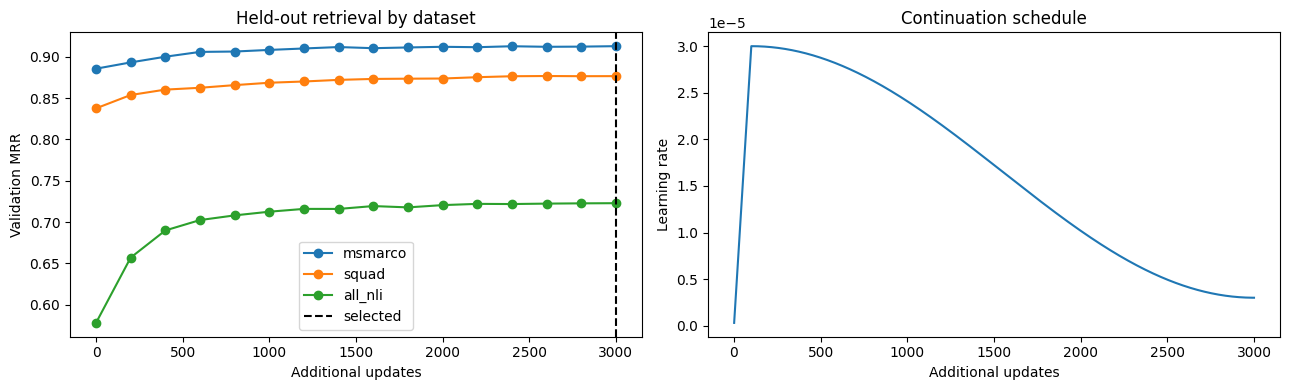

In [19]:
records={}
for line in (ROOT/'metrics.jsonl').read_text().splitlines():
    record=json.loads(line);records[record['step']]=record
records=[records[k] for k in sorted(records)]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for name in DATA:
    steps=[0]+[r['step'] for r in records if 'validation' in r]
    scores=[BASE_VALIDATION['by_source'][name]['selection_score']]+[r['validation']['by_source'][name]['selection_score'] for r in records if 'validation' in r]
    axes[0].plot(steps,scores,marker='o',label=name)
axes[0].axvline(SELECTED['additional_step'],color='black',ls='--',label='selected')
axes[0].set(xlabel='Additional updates',ylabel='Validation MRR',title='Held-out retrieval by dataset');axes[0].legend()
axes[1].plot([r['step'] for r in records],[r['lr'] for r in records])
axes[1].set(xlabel='Additional updates',ylabel='Learning rate',title='Continuation schedule')
fig.tight_layout();fig.savefig(ROOT/'evaluations'/'training-curves.png',dpi=160);plt.show()

In [20]:
def benchmark_bank(model,label):
    results=[]
    for name,b in load_benchmarks().items():
        docids=list(b['corpus']);qids=[q for q in b['queries'] if b['relevant'].get(q)]
        assert all(b['relevant'][q]<=set(docids) for q in qids)
        q=encode_profiles([b['queries'][i] for i in qids],model)
        p=encode_profiles(list(b['corpus'].values()),model)
        for depth in DEPTHS+([NUM_LAYERS] if label=='source' else []):
            for dim in DIMS:
                for mode,pdepth in [('same_exit',depth),('full_corpus',NUM_LAYERS)]:
                    metrics=retrieval_metrics(F.normalize(q[depth][:,:dim],dim=-1),F.normalize(p[pdepth][:,:dim],dim=-1),b['relevant'],qids,docids)
                    results.append(dict(variant='full' if depth==NUM_LAYERS else label,dataset=name,depth=depth,
                                        dimension=dim,mode=mode,queries=len(qids),**metrics))
        print(label,name,'complete',flush=True)
    return results

source_nano=ROOT/'evaluations'/'nano-source.json'
if source_nano.exists():
    saved=json.loads(source_nano.read_text());assert saved['contract']==CONTRACT_ID
    SOURCE_RESULTS=saved['results']
else:
    reference=source_bank();SOURCE_RESULTS=benchmark_bank(reference,'source');del reference
    write_json(source_nano,dict(contract=CONTRACT_ID,results=SOURCE_RESULTS))
RESULTS=SOURCE_RESULTS+benchmark_bank(bank,'continued')
write_json(ROOT/'evaluations'/'nano-comparison.json',dict(contract=CONTRACT_ID,selected=SELECTED,results=RESULTS))
with open(ROOT/'evaluations'/'nano-comparison.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(RESULTS[0]));writer.writeheader();writer.writerows(RESULTS)
print('Full-width query -> original full-depth corpus, NDCG@10:')
for name in load_benchmarks():
    for depth in DEPTHS:
        before=next(r['ndcg@10'] for r in RESULTS if r['variant']=='source' and r['dataset']==name and r['depth']==depth and r['dimension']==WIDTH and r['mode']=='full_corpus')
        after=next(r['ndcg@10'] for r in RESULTS if r['variant']=='continued' and r['dataset']==name and r['depth']==depth and r['dimension']==WIDTH and r['mode']=='full_corpus')
        print(f'{name:14} L={depth:2} {before:.4f} -> {after:.4f} delta={after-before:+.4f}')

source NanoMSMARCO complete
source NanoHotpotQA complete
continued NanoMSMARCO complete
continued NanoHotpotQA complete
Full-width query -> original full-depth corpus, NDCG@10:
NanoMSMARCO    L= 1 0.3685 -> 0.3740 delta=+0.0055
NanoMSMARCO    L= 2 0.3736 -> 0.3606 delta=-0.0131
NanoMSMARCO    L= 3 0.3315 -> 0.3515 delta=+0.0200
NanoMSMARCO    L= 4 0.3228 -> 0.3287 delta=+0.0059
NanoMSMARCO    L= 5 0.3659 -> 0.3683 delta=+0.0024
NanoMSMARCO    L= 6 0.3521 -> 0.3421 delta=-0.0101
NanoMSMARCO    L= 7 0.3747 -> 0.3505 delta=-0.0242
NanoMSMARCO    L= 8 0.3505 -> 0.3707 delta=+0.0202
NanoMSMARCO    L= 9 0.3954 -> 0.3988 delta=+0.0034
NanoHotpotQA   L= 1 0.4837 -> 0.5482 delta=+0.0645
NanoHotpotQA   L= 2 0.4841 -> 0.5485 delta=+0.0644
NanoHotpotQA   L= 3 0.4600 -> 0.5315 delta=+0.0715
NanoHotpotQA   L= 4 0.4861 -> 0.5157 delta=+0.0296
NanoHotpotQA   L= 5 0.4668 -> 0.5199 delta=+0.0530
NanoHotpotQA   L= 6 0.4808 -> 0.5271 delta=+0.0462
NanoHotpotQA   L= 7 0.5026 -> 0.5172 delta=+0.0146
NanoHot

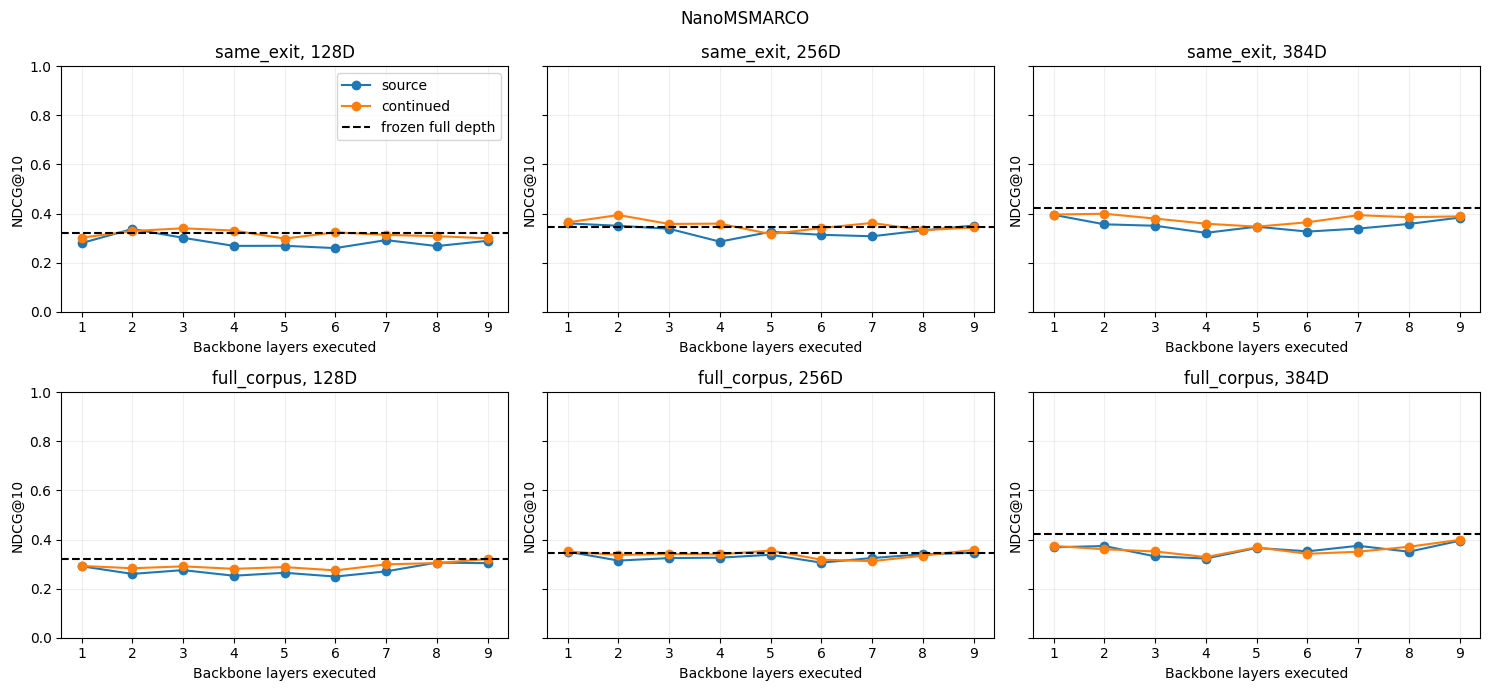

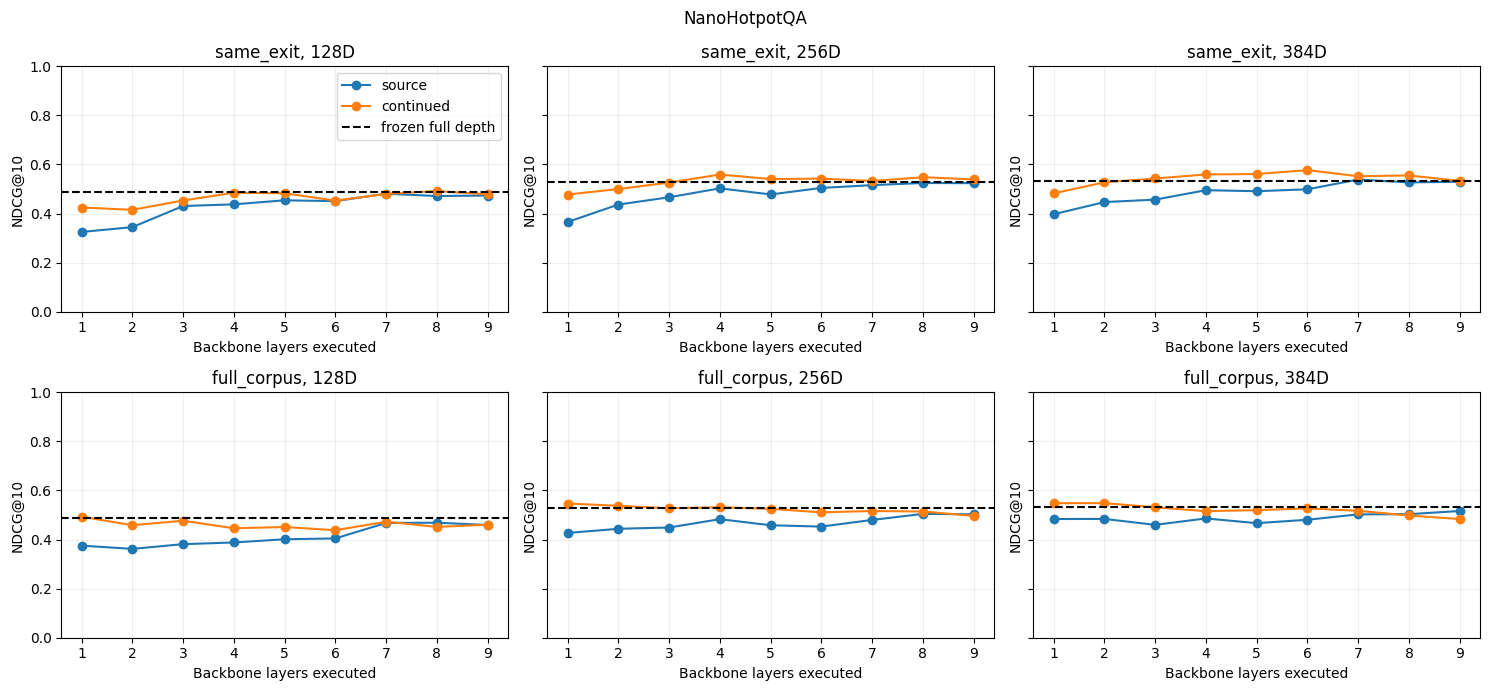

In [21]:
for dataset in load_benchmarks():
    fig,axes=plt.subplots(2,len(DIMS),figsize=(5*len(DIMS),7),squeeze=False,sharey=True)
    for row,mode in enumerate(['same_exit','full_corpus']):
        for col,dim in enumerate(DIMS):
            ax=axes[row,col]
            for label in ['source','continued']:
                ys=[next(r['ndcg@10'] for r in RESULTS if r['dataset']==dataset and r['mode']==mode and r['dimension']==dim and r['depth']==depth and r['variant']==label) for depth in DEPTHS]
                ax.plot(DEPTHS,ys,marker='o',label=label)
            full=next(r['ndcg@10'] for r in RESULTS if r['dataset']==dataset and r['variant']=='full' and r['mode']==mode and r['dimension']==dim)
            ax.axhline(full,color='black',ls='--',label='frozen full depth')
            ax.set(title=f'{mode}, {dim}D',xlabel='Backbone layers executed',ylabel='NDCG@10',ylim=(0,1));ax.grid(alpha=.2)
    axes[0,0].legend();fig.suptitle(dataset);fig.tight_layout()
    fig.savefig(ROOT/'evaluations'/f'{dataset}-before-after.png',dpi=160);plt.show()

## Export the selected model and check reload parity

One shared backbone/tokenizer plus one safetensors file containing the selected transformer exits.
Model provenance, pinned datasets and source/continuation step numbers accompany the weights.
Reload using the model definitions in this notebook. This is a PyTorch bundle, not an ONNX conversion.

In [22]:
EXPORT=ROOT/'exports'/f"transformer-step-{SELECTED['additional_step']:08d}"
if not EXPORT.exists():
    temp=ROOT/'exports'/('.uploading-'+uuid.uuid4().hex);temp.mkdir(parents=True)
    backbone.save_pretrained(temp/'backbone',safe_serialization=True);tokenizer.save_pretrained(temp/'tokenizer')
    save_file({k:v.detach().cpu().contiguous() for k,v in bank.state_dict().items()},str(temp/'transformer-exits.safetensors'))
    card=SOURCE_EXPORT/'UPSTREAM_MODEL_CARD.md'
    if card.exists():shutil.copyfile(card,temp/card.name)
    shutil.copytree(ROOT/'data-cards',temp/'data-cards')
    write_json(temp/'encoder.json',dict(contract=contract,selected=SELECTED,model_spec=SOURCE_MODEL_SPEC,
               source=ETTIN,initial_supervisor=GTE,backbone_sha=BACKBONE_SHA,max_length=CFG['max_length'],
               pooling='original_final_norm_then_masked_mean',normalize_after_truncation=True,
               head_definitions='ExitBank and ExitHead in 05_ettin_transformer_long.ipynb'))
    checksums={str(p.relative_to(temp)):file_sha(p) for p in sorted(temp.rglob('*')) if p.is_file()}
    write_json(temp/'COMMITTED.json',dict(contract=CONTRACT_ID,checksums=checksums))
    os.replace(temp,EXPORT)
manifest=json.loads((EXPORT/'COMMITTED.json').read_text());assert manifest['contract']==CONTRACT_ID
assert all(file_sha(EXPORT/relative)==sha for relative,sha in manifest['checksums'].items())
assert json.loads((EXPORT/'encoder.json').read_text())['selected']==SELECTED

reloaded_backbone=AutoModel.from_pretrained(EXPORT/'backbone',attn_implementation='sdpa').to(DEVICE).eval()
reloaded_tokenizer=AutoTokenizer.from_pretrained(EXPORT/'tokenizer')
probe=['Recover a forgotten password.','Books can be borrowed at the library.']
tokens=tokenize(probe)
reload_tokens=reloaded_tokenizer(probe,padding=True,truncation=True,max_length=CFG['max_length'],return_tensors='pt').to(DEVICE)
assert all(torch.equal(tokens[k],reload_tokens[k]) for k in tokens)
with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
    original=early_raw(tokens,NUM_LAYERS)
    restored=mean_pool(reloaded_backbone(**reload_tokens).last_hidden_state,reload_tokens['attention_mask'])
torch.testing.assert_close(original,restored,atol=1e-5,rtol=1e-4)
reloaded_bank=ExitBank().to(DEVICE).eval()
reloaded_bank.load_state_dict(load_file(str(EXPORT/'transformer-exits.safetensors')),strict=True)
with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):
    for depth in DEPTHS:
        a=early_raw(tokens,depth,bank).float();b=early_raw(tokens,depth,reloaded_bank).float()
        for dim in DIMS:torch.testing.assert_close(F.normalize(a[:,:dim],dim=-1),F.normalize(b[:,:dim],dim=-1),atol=1e-5,rtol=1e-4)
del reloaded_backbone,reloaded_bank;gc.collect();torch.cuda.empty_cache()
assert backbone_digest()==BACKBONE_SHA
print('Backbone and every exit/prefix reload parity passed:',EXPORT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/62 [00:00<?, ?it/s]

Backbone and every exit/prefix reload parity passed: /content/drive/MyDrive/encoder_experiments/ettin-transformer-long-01/exports/transformer-step-00003000


## Interpretation and provenance

Compare before/after NanoBEIR, per-source held-out MRR, and the full-depth corpus mode. A smaller training loss alone
is not evidence of better retrieval. The 50-query Nano sets remain small; their results are reporting-only for this run.
The added data are English retrieval/entailment examples, not a dedicated social-media corpus.
The frozen teacher may be imperfect on new domains, so alignment and labeled ranking can compete.

Datasets: [SQuAD pairs](https://huggingface.co/datasets/sentence-transformers/squad),
[AllNLI triplets](https://huggingface.co/datasets/sentence-transformers/all-nli), and the pilot's pinned MS MARCO split.
Cards and revisions are saved with the run. Source data terms continue to apply independently of the model's license.
GooAQ is omitted because its [upstream repository](https://github.com/allenai/gooaq) specifies non-commercial use.

Training design builds on [FastBERT](https://aclanthology.org/2020.acl-main.537/),
[EE-Tuning](https://arxiv.org/abs/2402.00518), and [Matryoshka-Adaptor](https://aclanthology.org/2024.emnlp-main.576/).
This run retains independent transformer heads, preserving the existing ablation as a directly comparable baseline.

## Final independent sanity check

Last cell: finite/nonzero outputs, repeatability, padding invariance at every dimension, full-depth preservation,
and the authored semantic probes for every exit. Quality flags are reported without treating a tiny probe set as a benchmark.

In [23]:
@torch.inference_mode()
def run_final_sanity(model,label):
    model.eval();texts=[case[i] for i in range(3) for case in SANITY_CASES]
    vectors=encode_profiles(texts,model)
    reports=[]
    for depth in DEPTHS+[NUM_LAYERS]:
        report=sanity_scores(vectors[depth],SANITY_CASES,DIMS)
        short=SANITY_CASES[0][0];long='A long passage describing the library and its books, the weather, and plans for a journey. '*3
        with torch.autocast('cuda',dtype=torch.bfloat16):
            a=early_raw(tokenize([short]),depth,model).float()
            repeat=early_raw(tokenize([short]),depth,model).float()
            padded=early_raw(tokenize([short,long]),depth,model)[:1].float()
        repeat_ok=bool(torch.allclose(a,repeat,atol=1e-5,rtol=1e-4))
        padding={str(dim):float(F.cosine_similarity(a[:,:dim],padded[:,:dim]).item()) for dim in DIMS}
        passed=report['finite'] and report['nonzero'] and repeat_ok and all(v>.999 for v in padding.values()) and all(v['nonzero_prefix'] for v in report['profiles'].values())
        report.update(label=label,depth=depth,repeatable=repeat_ok,padding_cosines=padding,plumbing_passed=bool(passed))
        report['quality_flags']=[f'{dim}D: inspect weak ranking or collapsed vectors' for dim,r in report['profiles'].items() if r['easy_accuracy']<=.5 or r['normalized_spread']<1e-4]
        reports.append(report)
        for dim,r in report['profiles'].items():
            print(f"{label:10} L={depth:2} D={dim:>3} plumbing={'PASS' if passed else 'FAIL'} easy={r['easy_accuracy']:.1%} hit1={r['hit_at_1']:.1%} spread={r['normalized_spread']:.4f}")
    return reports

reference=source_bank();SOURCE_SANITY=run_final_sanity(reference,'source');del reference
FINAL_SANITY=run_final_sanity(bank,'continued')
unchanged=backbone_digest()==BACKBONE_SHA
path=ROOT/'evaluations'/f'sanity-{time.time_ns()}.json'
write_json(path,dict(contract=CONTRACT_ID,selected=SELECTED,backbone_unchanged=unchanged,source=SOURCE_SANITY,continued=FINAL_SANITY))
print('Saved:',path,'\nUse held-out retrieval to judge improvement; these probes are diagnostic.')
assert unchanged and all(r['plumbing_passed'] for r in SOURCE_SANITY+FINAL_SANITY), 'Plumbing failed; inspect the saved report.'

source     L= 1 D=128 plumbing=PASS easy=100.0% hit1=83.3% spread=0.5511
source     L= 1 D=256 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5515
source     L= 1 D=384 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5416
source     L= 2 D=128 plumbing=PASS easy=100.0% hit1=83.3% spread=0.5424
source     L= 2 D=256 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5605
source     L= 2 D=384 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5521
source     L= 3 D=128 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5802
source     L= 3 D=256 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5885
source     L= 3 D=384 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5655
source     L= 4 D=128 plumbing=PASS easy=100.0% hit1=83.3% spread=0.5904
source     L= 4 D=256 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5874
source     L= 4 D=384 plumbing=PASS easy=100.0% hit1=91.7% spread=0.5802
source     L= 5 D=128 plumbing=PASS easy=100.0% hit1=83.3% spread=0.5883
source     L= 5 D=256 plumbing=PASS easy=100.0% hit